<a href="https://colab.research.google.com/github/achmadanval/PCVK-2026/blob/main/PCVK_week_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

# Percobaan 1

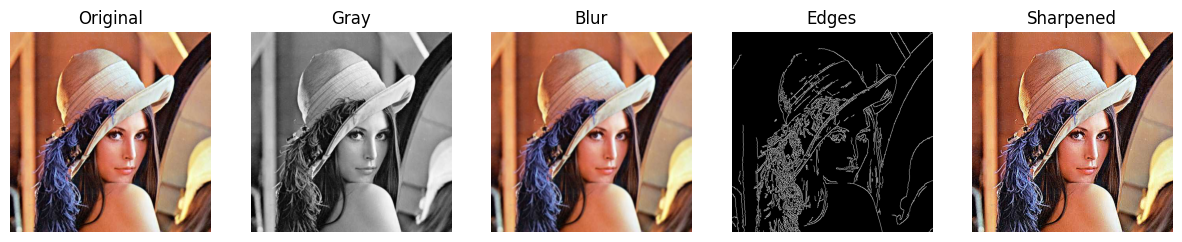

In [ ]:
def show_side_by_side(images, title, figsize=(15, 5)):
  plt.figure(figsize=figsize)
  for i,(img, title) in enumerate(zip(images, title)):
    if len(img.shape) == 2:
      plt.subplot(1, len(images), i+1)
      plt.imshow(img, cmap='gray')
    else:
      plt.subplot(1, len(images), i+1)
      plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
  plt.show()

img = cv.imread('/content/drive/MyDrive/lena.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(img, (7,7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY),100 ,200)
sharpen_kernel = np.array([[0,-1,0], [-1,5,-1], [0,-1,0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)
show_side_by_side([img, img_gray, blur, edges, sharpened], ['Original', 'Gray', 'Blur', 'Edges', 'Sharpened'])


# Percobaan 2

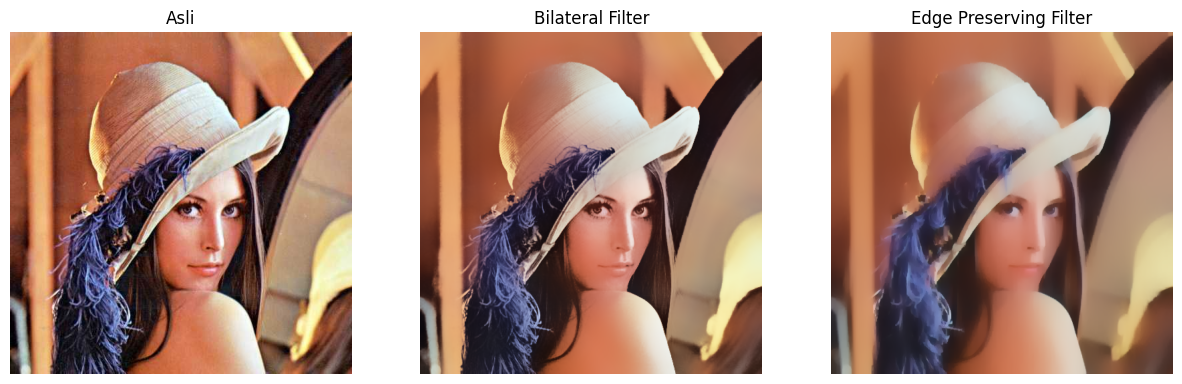

In [ ]:
#Filter Modern dari OpenCv
#Billateral Filter (Edge-Preserving)
bilateral = cv.bilateralFilter(img, 50, 100, 100)

#Edge Preserving filter (alternatif Guided Filter)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side([img, bilateral, edge_preserve],
                  ["Asli", "Bilateral Filter", "Edge Preserving Filter"])

# Percobaan 3

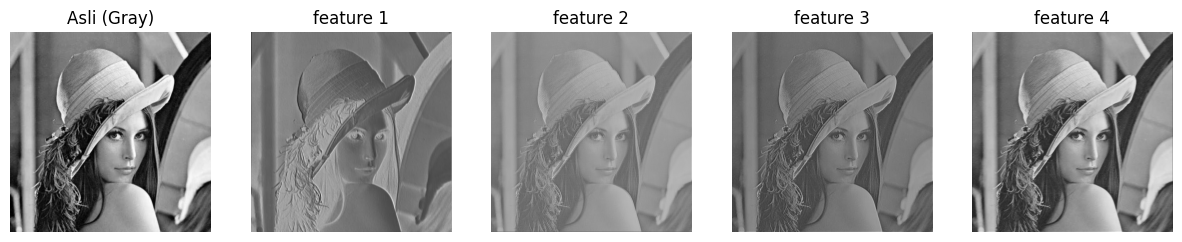

In [ ]:
#Filter Deature Map yang digunakan pada CNN, Alkukan running code bagian ini beberpa kali dan perhatikan hasilnya
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
  def __init__(self):
    super(SimpleCNN, self).__init__()
    self.convl = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

  def forward(self,x):
    return self.convl(x)

model = SimpleCNN()


#Ubah gambar ke tensor

img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0)/255.0

#Hasil CNN
with torch.no_grad():
  features = model(img_tensor)

#Visualisasi Feature maps
feature_maps = [features[0, i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray]+feature_maps, ["Asli (Gray)"] + [f"feature {i+1}"  for i in range (len(feature_maps))])

# Percobaan 4

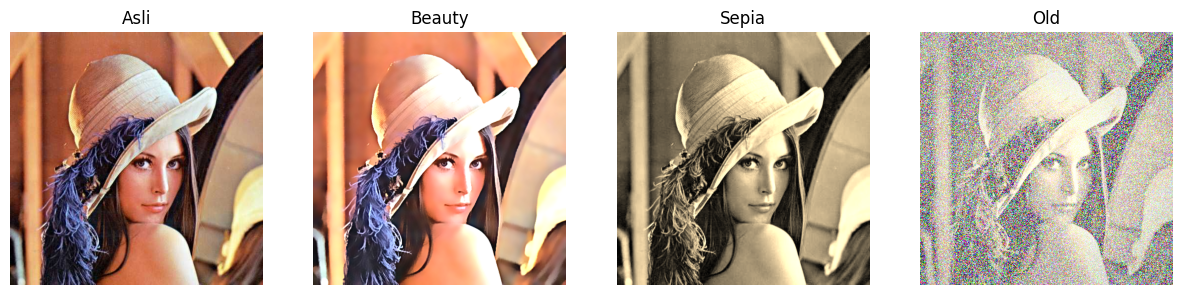

In [ ]:

#1. Beauty Filter
# step 1: smootihing kulit dengan bilateral filter
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

# Step 2: Unsharp masking (pertama mata/bibir)
gaussian = cv.GaussianBlur(smooth, (0,0), 3)
sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)

# Step 3: Brightness & contrast
alpha = 1.2
beta = 15
beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)

#=================
#2. Old/Vintage Filter
#=================
#Step 1: Sepia tone
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

#Step 2: Vignette
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols*0.6)
kernel_y = cv.getGaussianKernel(rows, rows*0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
  vignette[:,:,i] = vignette[:,:,i] * mask

#Step 3: Noise/Grain
noise = np.random.normal(0, 15, vignette.shape).astype(np.uint16)
old_img = np.clip(vignette.astype(np.int16)+noise, 0, 255).astype(np.uint8)

show_side_by_side([img, beauty, sepia, old_img],
                  ["Asli", "Beauty", "Sepia", "Old"])


# Percobaan 5

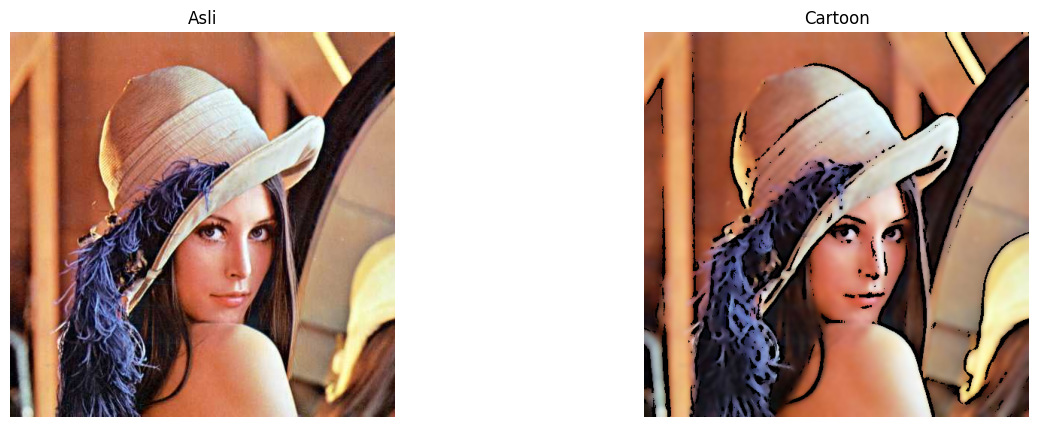

In [ ]:
#Filter anime/cartoon
#Step 1: Edge detection (pakai median blur dulu agar gambar menjadi lebih halus)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
grat_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(grat_blur, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 9, 9)

#Step 2: Bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

#Step 3: Gabungkan (Caartoonize)
cartooon = cv.bitwise_and(color, color, mask=edges)

show_side_by_side([img, cartooon],
                  ["Asli", "Cartoon"])

# Percobaan 6

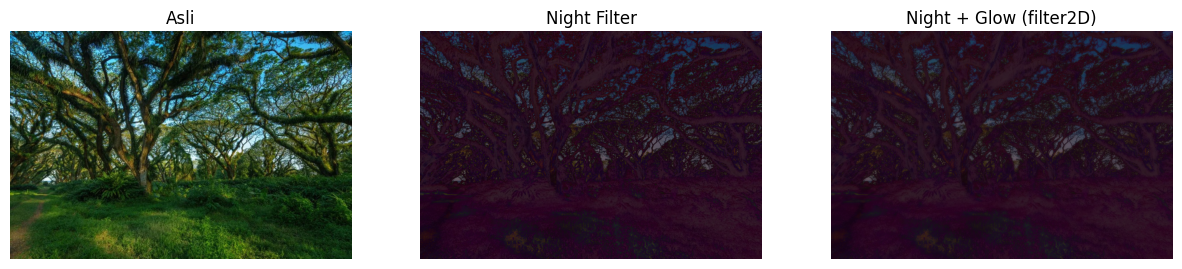

In [ ]:
#night Filter
img = cv.imread('/content/drive/MyDrive/Hutan.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

#Step 1: Gelapkan (Contrast turun, brightness negatif)
night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

#Step 2: tambah bias biru
blur_tint = np.full_like(night, (50, 0 ,100)) #Format BGR
night = cv.addWeighted(night, 0.8, blur_tint, 0.2, 0)

#Step 3:
kernel = np.ones((15,15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel)

#Kombinasi asli + glow
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side([img, night, night_glow],
                  ["Asli", "Night Filter", "Night + Glow (filter2D)"])



# Percobaan 7

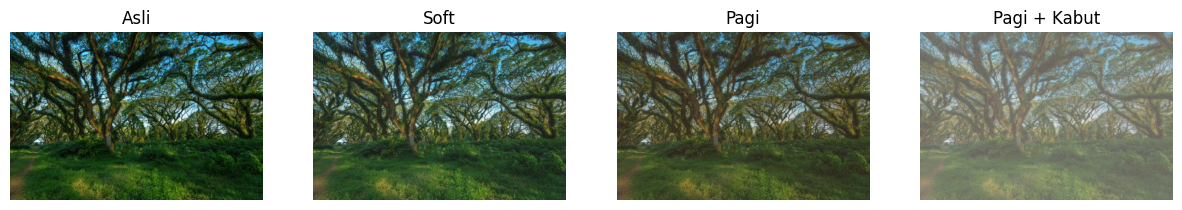

In [ ]:
#Filter Suasana Pagi dan kabut

#Step 1: Kurangi Contras & Cerahkan

alpha = 0.9
beta = 20
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

#Step : Tambahkan warm tone (Kemerahan  / orange )
warm_tint = np.full_like(soft, (40,70,120)) #Format BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

#Step 3 : Tambahkan haze (kabut tipis) dengan filter2D

#Kernel blur gaussian-like untuk menciptakan efek kabut
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T #jadikan 2D Kernel
kabut = cv.filter2D(pagi, -1, kernel)

#tambahkan layer putih untuk kabut lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img, soft, pagi, kabut],
                  ["Asli", "Soft", "Pagi", "Pagi + Kabut"])



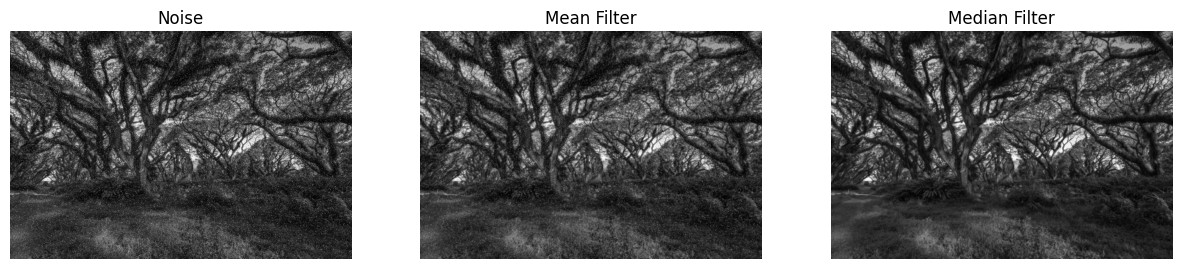

In [ ]:
#1 Tugas Analisis: Perbandingan MEan Filter dan Median Filter pada Noise salt and pepper

#a. Tambahkan noise bintik bintk hitam putih(salt and pepper) ke citra keabuan (grayscale)

noise_img = img_gray.copy()
num_noise = int(0.05 * noise_img.size)

#menambahkan salt (titik putih)

for i in range(num_noise // 2):
  x = np.random.randint(0, noise_img.shape[0])
  y = np.random.randint(0, noise_img.shape[1])
  noise_img[x, y] = 255

#menambahkan pepper (titik hitam)
for i in range(num_noise // 2):
  x = np.random.randint(0, noise_img.shape[0])
  y = np.random.randint(0, noise_img.shape[1])
  noise_img[x, y] = 0

#b. Terapkan Mean Filter (3 x 3) dan Median Filter (3 x 3)
mean_filter = cv.blur(noise_img, (3, 3))
median_filter = cv.medianBlur(noise_img, 3)

#c. Tampilkan hasilnya

show_side_by_side([noise_img, mean_filter, median_filter],
                  ["Noise", "Mean Filter", "Median Filter"])

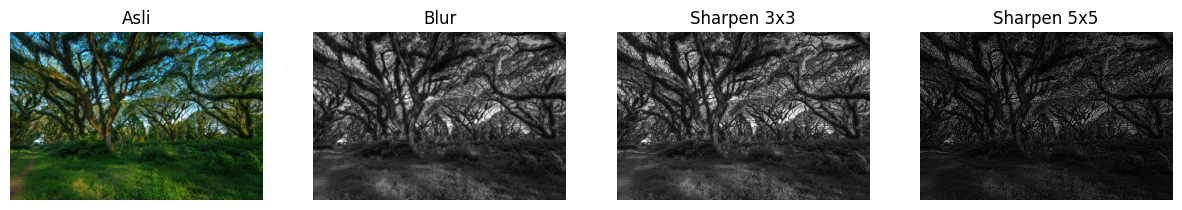

In [ ]:
#2 Tugas Evaluasi : Pemilihan ukuran kernel terbaik untuk menajamkan citra

#A. Membuat kernel penajaman ukuran 3x3 dan 5x5

sharpen_3x3 = np.array([[ 0, -1,  0],
                        [-1,  5, -1],
                        [ 0, -1,  0]])

sharpen_5x5 = np.array([[-1, -1, -1, -1, -1],
                        [-1,  1,  2,  1, -1],
                        [-1,  2,  7,  2, -1],
                        [-1,  1,  2,  1, -1],
                        [-1, -1, -1, -1, -1]]) / 7.0

#B. Terapkan pada citra yang sedikit buram
img_blur =  cv.GaussianBlur(img_gray, (3,3), 0)
sharp_3x3_result = cv.filter2D(img_blur, -1, sharpen_3x3)
sharp_5x5_result = cv.filter2D(img_blur, -1, sharpen_5x5)

#C. Tampilkan hasilnya
show_side_by_side([img, img_blur, sharp_3x3_result, sharp_5x5_result],
    ["Asli", "Blur", "Sharpen 3x3", "Sharpen 5x5"]
)

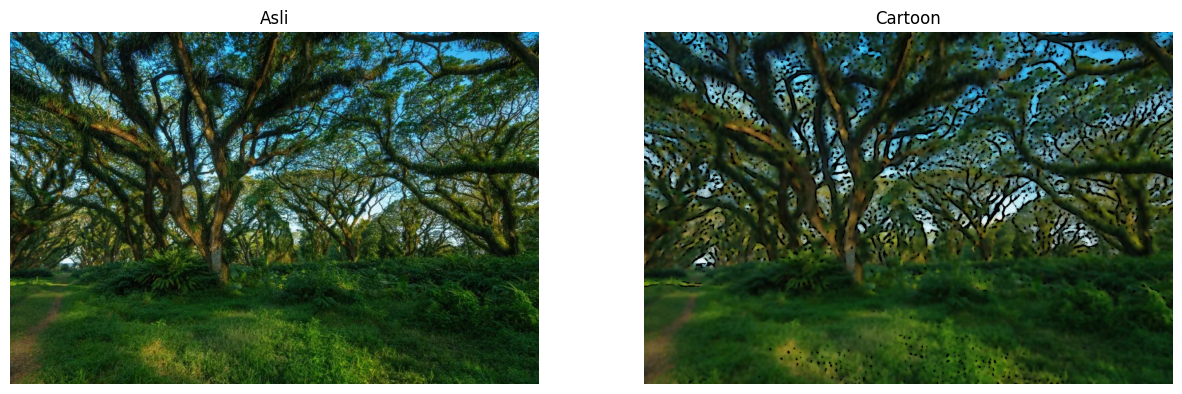

In [ ]:
#3.  Tugas Kreasi : Filter kartun sederhana
#Filter anime/cartoon
#Step 1: Edge detection (pakai median blur dulu agar gambar menjadi lebih halus)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
grat_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(grat_blur, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 9, 9)

#Step 2: Bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

#Step 3: Gabungkan (Caartoonize)
cartooon = cv.bitwise_and(color, color, mask=edges)

show_side_by_side([img, cartooon],
                  ["Asli", "Cartoon"])
